# Анализ оптовых продаж аудиотехники
Расширенный учебный проект на данных karpov.courses. Март 2024.

Цель: собрать разрозненные выгрузки, проверить данные и исследовать продажи, отмены, ассортимент и клиентов. Все результаты ниже получены исполнением кода.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.analysis import load_data, analyze
full, products, currency, manifest = load_data(ROOT / 'data/raw')
results = analyze(full, products)
print(manifest.groupby('table').agg(files=('file', 'size'), rows=('rows', 'sum')).to_string())

              files  rows
table                    
order_status    178   346
orders          178  4603
products         26  1677


## 1. Структура и качество
Одна строка — один товар в заказе. Даты, менеджеры и категории берутся из папок. Функция `load_data` проверяет ключи, пропуски, цены, количества и курсы. Объединения many-to-one сохраняют число строк.

In [2]:
print(full.head(5).to_string(index=False))
print('\nСтрок:', len(full), 'Заказов:', full.order_id.nunique())

     order_id  product_id  quantity               manager       date  client_id    status  id                     name  price              category  currency_rate        brand    price_rub       revenue
ABID-18767701          72        30 Маргарита Камертонова 2024-03-11         44 confirmed  72 Beyerdynamic, DT 990 PRO 158.91    Проводные наушники        90.7493 Beyerdynamic 14420.971263 432629.137890
ABID-18767701         509        40 Маргарита Камертонова 2024-03-11         44 confirmed 509           Heco, Stay 300  43.95    Проводные наушники        90.7493         Heco  3988.431735 159537.269400
ABID-18767701         555        26 Маргарита Камертонова 2024-03-11         44 confirmed 555            JBL, Charge 4 159.13 Беспроводная акустика        90.7493          JBL 14440.936109 375464.338834
ABID-18767701         557        30 Маргарита Камертонова 2024-03-11         44 confirmed 557            JBL, Xtreme 2 308.70 Беспроводная акустика        90.7493          JBL 28014.308910

## 2. Основные показатели
Выручка рассчитывается по принятой в курсе формуле: количество × цена USD × курс. Средний чек — выручка подтверждённых заказов / число уникальных подтверждённых заказов. Это не прибыль.

In [3]:
s = results['summary']
for key in ['revenue','confirmed_orders','canceled_orders','cancel_rate','average_order_value']:
    print(key, ':', round(s[key], 4))

revenue : 2038231821.5649
confirmed_orders : 309
canceled_orders : 37
cancel_rate : 0.1069
average_order_value : 6596219.4873


## 3. Динамика
Включаем все календарные дни между первой и последней датой. Для дней без подтверждённых заказов средний чек не определён.

      date  confirmed  canceled      revenue  average_order_value
2024-03-01         20         2 1.554118e+08         7.770588e+06
2024-03-02          2         0 1.197167e+07         5.985834e+06
2024-03-03          1         0 2.548418e+06         2.548418e+06
2024-03-04         10         0 6.404993e+07         6.404993e+06
2024-03-05         18         0 8.952724e+07         4.973735e+06
2024-03-06         13         1 1.107687e+08         8.520669e+06
2024-03-07         13         1 9.102331e+07         7.001793e+06
2024-03-08          1         0 1.609147e+06         1.609147e+06
2024-03-09          0         1 0.000000e+00                  NaN
2024-03-10          2         1 8.929309e+06         4.464655e+06
2024-03-11         11         1 8.910847e+07         8.100770e+06
2024-03-12         13         2 8.761460e+07         6.739584e+06
2024-03-13          5        19 3.669156e+07         7.338312e+06
2024-03-14         34         0 2.222701e+08         6.537355e+06
2024-03-15

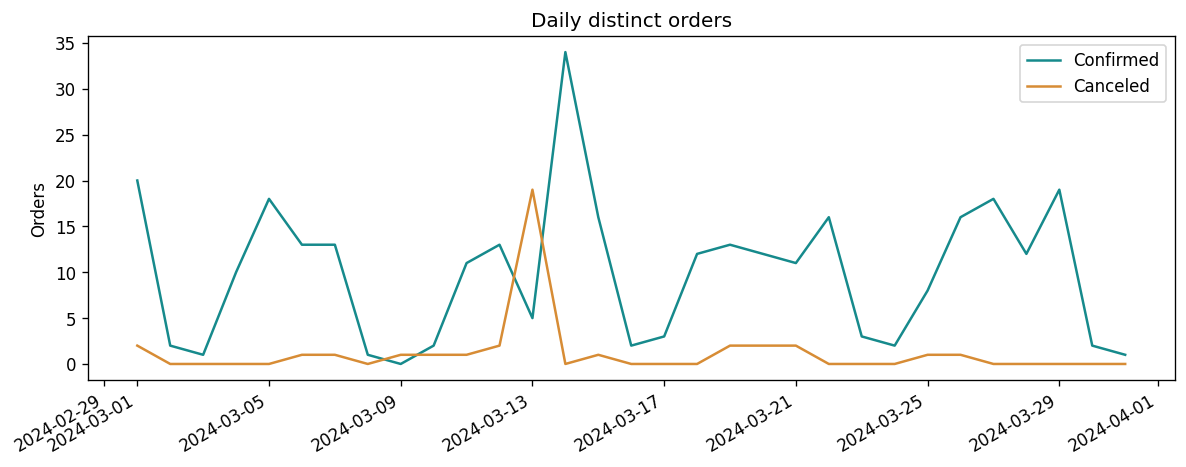

In [4]:
daily = results['daily']
print(daily.to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.date, daily.confirmed, label='Confirmed', color='#168a8c')
ax.plot(daily.date, daily.canceled, label='Canceled', color='#d78c35')
ax.set(title='Daily distinct orders', ylabel='Orders')
ax.legend(); fig.autofmt_xdate(); fig.tight_layout(); plt.show()

## 4. Проверка повторного оформления
Сравниваем полные корзины `(product_id, quantity)`, клиента и менеджера на соседних днях. Сопоставление один-к-одному исключает раздувание числа совпадений. Это более строгий критерий, чем совпадение числа разных товаров и общего количества штук.

In [5]:
pairs = results['pairs']
print(pairs[['order_id_canceled','order_id_confirmed','date_canceled','date_confirmed','client_id','manager','ambiguous']].to_string(index=False))
print('\nPairs:', len(pairs))
print('Share of March 14 confirmed orders:', round(len(pairs) / int(daily.loc[daily.date.eq('2024-03-14'),'confirmed'].iloc[0]) * 100, 2), '%')

order_id_canceled order_id_confirmed date_canceled date_confirmed  client_id               manager  ambiguous
    AFIH-00611801      FDEB-71487438    2024-03-13     2024-03-14         43    Алексей Саксофонов      False
    BBFJ-27674101      UETB-44283966    2024-03-13     2024-03-14         73    Ксения Балалайкина      False
    CLBQ-63032648      IECD-18739530    2024-03-13     2024-03-14         60      Виктор Тромбонов      False
    CYJY-07359557      WNMY-98871151    2024-03-13     2024-03-14         56   Екатерина Тарелкина      False
    GHGB-88045656      JUGG-73806170    2024-03-13     2024-03-14          7    Ксения Балалайкина      False
    JEIF-69283221      EPBF-14743479    2024-03-13     2024-03-14         94      Виктор Тромбонов      False
    JQQO-28609300      OWZC-14247946    2024-03-13     2024-03-14         93      Виктор Тромбонов      False
    KJJS-03491897      GRCH-73394464    2024-03-13     2024-03-14         66    Алексей Саксофонов      False
    MIGZ-6

**Вывод:** найдено 16 совпадений (47,06% подтверждённых заказов 14 марта). Причину нельзя установить без логов. 13 марта были также 5 подтверждений: утверждение о полной остановке продаж было бы неверным.

## 5. Ассортимент и ABC
Класс A включает товар, на котором накопленная доля пересекает 80%; B — следующий набор до пересечения 95%; остальные проданные товары — C. Непроданные товары выделены отдельно.

In [6]:
p = results['product_sales']
print(p.groupby('abc').agg(products=('id','size'), revenue=('revenue','sum')).to_string())
print('\nBrands for review:')
print(results['coverage'].query('products >= 15 and unsold_share > 0.5').to_string(index=False))
print('\nLeading brands:')
print(results['brands'].head(10).to_string(index=False))

          products       revenue
abc                             
A              425  1.630957e+09
B              357  3.058061e+08
C              398  1.014687e+08
No sales       497  0.000000e+00

Brands for review:
  brand  products  sold_products  unsold_products  unsold_share
Marantz        22              3               19      0.863636
   Dali        67             18               49      0.731343
Pioneer       103             33               70      0.679612
    KEF        82             28               54      0.658537

Leading brands:
        brand      revenue  orders  units
          JBL 2.665961e+08     264  11859
         Heco 2.388163e+08     229   7029
      Klipsch 2.039024e+08     205   5767
       Yamaha 1.658651e+08     218   6592
          KEF 1.465101e+08      73   1964
       Magnat 1.141989e+08     154   3745
   Wharfedale 1.129230e+08     127   3139
Harman Kardon 1.035031e+08     125   3939
  Q-Acoustics 1.021578e+08     117   2505
         Dali 8.353668e+0

## 6. Менеджеры
Сопоставляем объём, выручку, средний чек и отмены. Без данных о распределении клиентов и нагрузке эти различия нельзя трактовать как чистую эффективность сотрудника.

In [7]:
print(results['managers'].to_string(index=False))

              manager  total_orders  canceled  confirmed      revenue  cancel_rate  average_order_value  revenue_share  order_share
Маргарита Камертонова            55         7         48 3.473886e+08     0.127273         7.237262e+06       0.170436     0.155340
     Виктор Тромбонов            55         5         50 3.188999e+08     0.090909         6.377999e+06       0.156459     0.161812
     Максим Барабанов            43         3         40 2.401478e+08     0.069767         6.003695e+06       0.117822     0.129450
   Владимир Ударников            36         5         31 2.084865e+08     0.138889         6.725370e+06       0.102288     0.100324
   Алексей Саксофонов            30         3         27 1.953435e+08     0.100000         7.234946e+06       0.095840     0.087379
   Ксения Балалайкина            32         5         27 1.817621e+08     0.156250         6.731931e+06       0.089176     0.087379
  Екатерина Тарелкина            32         4         28 1.781576e+08     0.

## 7. Клиентская концентрация
Доля крупнейших покупателей показывает структуру выручки. На одном месяце нельзя обоснованно прогнозировать отток.

In [8]:
print(results['clients'].head(10).to_string(index=False))
print('Top 5 share:', round(s['top5_client_share'] * 100, 2), '%')

 client_id      revenue  orders  units  revenue_share  cumulative_share
        94 6.768533e+07      11   2762       0.033208          0.033208
        82 6.425253e+07       8   2630       0.031524          0.064732
        59 6.370158e+07       8   2020       0.031253          0.095985
        99 6.156216e+07       7   2510       0.030204          0.126189
        14 6.002728e+07       9   2481       0.029451          0.155639
        83 6.000468e+07      10   2190       0.029440          0.185079
        33 5.929342e+07       6   1681       0.029091          0.214169
        88 5.877664e+07       9   1849       0.028837          0.243007
        49 5.716430e+07       9   2368       0.028046          0.271053
        24 5.509377e+07       6   1753       0.027030          0.298083
Top 5 share: 15.56 %


## 8. Проверка согласованности
Итоги по дням, брендам и менеджерам должны совпадать с общей выручкой. Тесты в `tests/test_analysis.py` дополнительно проверяют точность сравнения корзин и неоднозначные соответствия.

In [9]:
for name in ['daily','brands','categories','clients','managers','product_sales']:
    total = results[name].revenue.sum()
    assert abs(total - s['revenue']) < 0.001, name
    print(name, 'reconciled')

daily reconciled
brands reconciled
categories reconciled
clients reconciled
managers reconciled
product_sales reconciled


## Рекомендации и ограничения
Проверить причины отмен и технические логи за 13 марта. Изучить доступность и историю спроса товаров без продаж перед изменением ассортимента. Сопоставить менеджеров с учётом портфелей клиентов.

Источник — учебные данные karpov.courses. Нет себестоимости, остатков, логов CRM и истории за другие месяцы. Итоги описывают данные и не подтверждают реальный коммерческий эффект. Дашборд: `../reports/dashboard.html`.